In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import LabelEncoder


from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb


from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

import joblib

sns.set_style("whitegrid")
plt.rcParams['axes.unicode_minus'] = False

In [104]:
df = pd.read_csv('../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [106]:
df.drop(('customerID'),axis=1 , inplace=True)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

categorical = ['gender' , 'Partner' ,'Dependents' , 'PhoneService' , 'MultipleLines' , 'InternetService' 
               , 'OnlineSecurity' , 'OnlineBackup' , 'DeviceProtection' , 'TechSupport' , 'StreamingTV', 
               'StreamingMovies' , 'Contract' , 'PaperlessBilling' , 'PaymentMethod' , 'Churn']

le = LabelEncoder()
for i in categorical:
    df[i] = le.fit_transform(df[i])
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [107]:
df.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.504756,0.162147,0.483033,0.299588,32.371149,0.903166,0.940508,0.872923,0.790004,0.906432,0.904444,0.797104,0.985376,0.992475,0.690473,0.592219,1.574329,64.761692,2281.916928,0.265370
std,0.500013,0.368612,0.499748,0.458110,24.559481,0.295752,0.948554,0.737796,0.859848,0.880162,0.879949,0.861551,0.885002,0.885091,0.833755,0.491457,1.068104,30.090047,2265.270398,0.441561
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,35.500000,402.225000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,2.000000,70.350000,1397.475000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,89.850000,3786.600000,1.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,3.000000,118.750000,8684.800000,1.000000


Churn
0    5174
1    1869
Name: count, dtype: int64

 0 73.5%
 1 26.5%


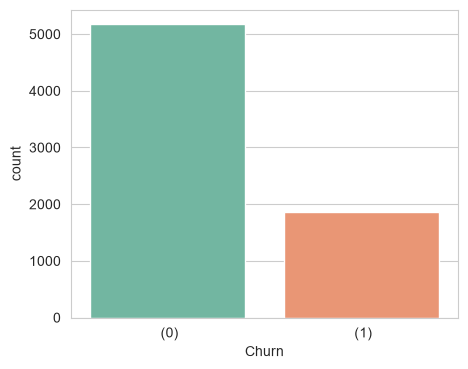

In [108]:
counts = df['Churn'].value_counts()
print(counts)
print(f"\n 0 {counts[0]/len(df):.1%}")
print(f" 1 {counts[1]/len(df):.1%}")

plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data=df, hue='Churn', palette='Set2', legend=False)
plt.xticks([0,1], [' (0)', ' (1)'])
plt.show()

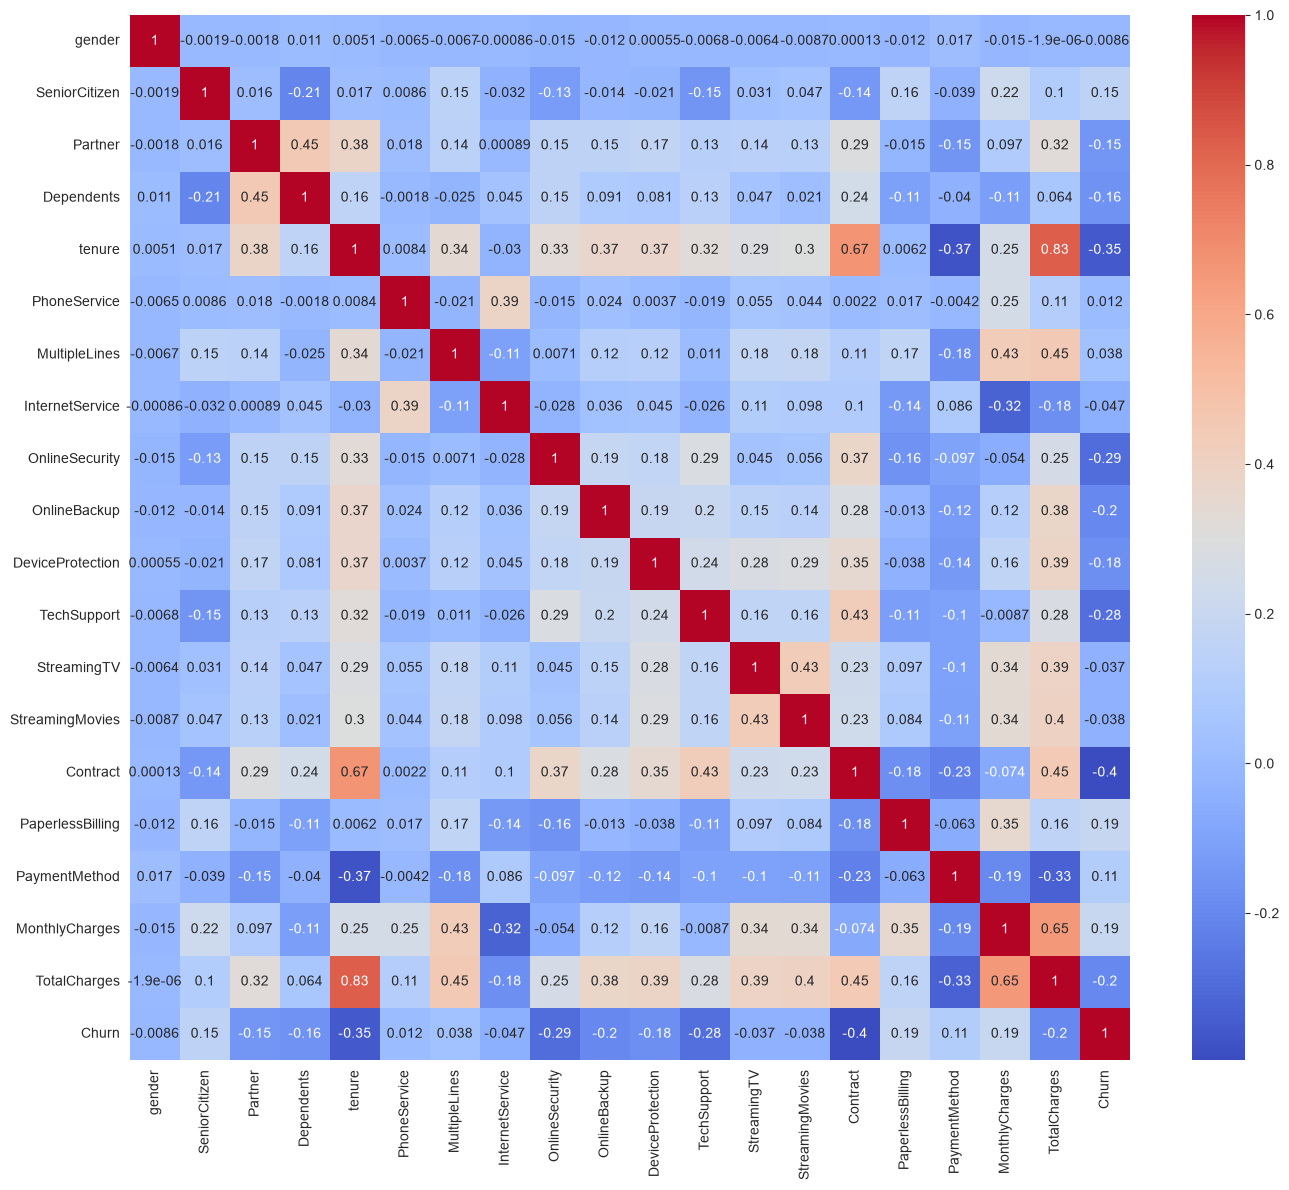

In [109]:
plt.figure(figsize=(14,12))
sns.heatmap(df.corr() , annot=True ,cmap='coolwarm')
plt.tight_layout()

In [110]:
X = df.drop('Churn' , axis=1)
y = df['Churn']

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=88)

In [111]:
def make_pipeline(model):
    return Pipeline([
        ('scaler' , StandardScaler()),
        ('model' , model)
    ])

In [112]:
baseline = DummyClassifier(strategy='most_frequent', random_state=42)
baseline.fit(X_train, y_train)
baseline_acc = baseline.score(X_test, y_test)
print(f"Baseline: {baseline_acc:.2%}")

Baseline: 73.39%


In [113]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=5000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf'),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost' : xgb.XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6)
}

In [114]:
results = {}

for name , model in models.items():
    pipe = make_pipeline(model) 
    scores = cross_val_score(pipe , X_train , y_train , cv=5 , scoring='accuracy')
    results[name] = scores
    print(f"{name:20s} average : {scores.mean():.4f}  (± {scores.std():.4f})")
best_name = max(results, key=lambda name: results[name].mean())
print(f"Cross Validation winner is : {best_name}  (average predict : {results[best_name].mean():.4f})")


Logistic Regression  average : 0.8030  (± 0.0180)
KNN                  average : 0.7483  (± 0.0087)
SVM                  average : 0.7980  (± 0.0151)
Decision Tree        average : 0.7275  (± 0.0120)
Random Forest        average : 0.7929  (± 0.0130)
Gradient Boosting    average : 0.8016  (± 0.0115)
XGBoost              average : 0.8014  (± 0.0095)
Cross Validation winner is : Logistic Regression  (average predict : 0.8030)


In [115]:
param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10, 100]
    },
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9, 11],
        'model__weights': ['uniform', 'distance']
    },
    'SVM': {
        'model__C': [0.1, 1, 10],
        'model__gamma': ['scale', 'auto']
    },
    'Decision Tree': {
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_split': [2, 5, 10]
    },
    'Random Forest': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [None, 5, 10, 15]
    },
    'Gradient Boosting': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_depth': [3, 5]
    },
    'XGBoost': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_depth': [3, 6]
    }
}

grid = GridSearchCV(
    estimator=make_pipeline(models[best_name]),
    param_grid=param_grids[best_name],
    cv=5,
    scoring='f1',
    verbose=1
)

grid.fit(X_train, y_train)

print(f"Best model     : {best_name}")
print(f"Best params    : {grid.best_params_}")
print(f"Best CV score  : {grid.best_score_:.4f}")
print(f"CV score before tuning : {results[best_name].mean():.4f}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best model     : Logistic Regression
Best params    : {'model__C': 1}
Best CV score  : 0.5954
CV score before tuning : 0.8030


In [116]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

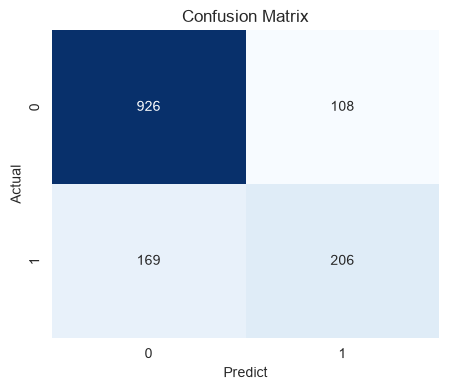

In [117]:
cm = confusion_matrix(y_test, y_pred)

labels = ['0', '1']

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [118]:
joblib.dump(best_model, 'breast_cancer_model.joblib')
print("saved")

saved
